# Grammar Scoring from Spoken English
SHL Hiring Assessment 2026

## The challenge
Given a 45-60 second spoken answer, predict a grammar score between 0 and 5. There are 769 labelled clips for training and 216 clips for testing, and submissions are judged by RMSE and Pearson correlation.

## My approach
I treated the problem as two questions: *what* does the person say, and *how* do they sound while saying it?

1. What they say. Whisper transcribes each clip and keeps fillers, restarts and pauses, since these carry signal. From the transcript I build fluency measures (speed, pauses, repetition, sentence length) and use a small language model to see how predictable the wording is. Fluent, grammatical text tends to be more predictable.
2. How they sound. Three pretrained speech models turn the raw audio into numeric summaries.
3. Putting it together. A simple model is trained on each group of features, and a weighted blend combines their predictions into one score.

## The most important decision: validation
The same speakers appear many times in the training data, while the test set contains new people. A random split would let a model score well by recognising voices rather than judging grammar. To prevent this, I group clips by speaker and make sure no speaker appears on both sides of any split. Every score in this notebook is therefore measured on speakers the model has not seen, which is the honest estimate of how it will do on the test set.

## Design choices
- Open models only. No paid APIs or keys are needed.
- Reproducible. Slow steps are saved after the first run, so reruns are quick.
- Score 0. The 37 clips with score 0 look like "not a real answer" rather than the bottom of the scale, so they are kept out of modelling. No test clip resembles them.

## Where to find things
Each section has a short note above its code. The report and the training RMSE are at the end of the notebook.

## 1. Setup

This cell gets everything ready: imports, folder paths, a fixed random seed and a few small helper functions.

- `locate_file` finds a file and reuses saved results from earlier runs, so slow steps don't have to be repeated.
- `root_mse` computes RMSE, the score used in this competition.
- `require` stops with a clear message if an earlier cell was skipped.

In [1]:
# Cell 1 | setup, paths, helpers
import gc, glob, json, os, re, shutil, time, warnings

import numpy as np
import pandas as pd
import soundfile as sf
import torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

OUT_DIR = "/kaggle/working"
IN_DIR = "/kaggle/input"
CACHE_DIR = f"{OUT_DIR}/cache"
os.makedirs(CACHE_DIR, exist_ok=True)

PALETTE = {"train": "#2A9D8F", "test": "#E76F51", "accent": "#264653", "warn": "#E9C46A"}
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 110,
})

CACHE_EXT = (".npy", ".parquet", ".jsonl")


def locate_file(name):
    """Return a usable path for `name`, or None. Cache artefacts from attached inputs are copied into this run's cache."""
    local = f"{CACHE_DIR}/{name}"
    if os.path.exists(local):
        return local
    hits = glob.glob(f"{OUT_DIR}/**/{name}", recursive=True) + glob.glob(f"{IN_DIR}/**/{name}", recursive=True)
    if not hits:
        return None
    if hits[0].startswith(IN_DIR) and name.endswith(CACHE_EXT):
        shutil.copy(hits[0], local)
        return local
    return hits[0]


def release_gpu():
    gc.collect()
    torch.cuda.empty_cache()


def root_mse(a, b):
    return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))


def require(*names):
    missing = [n for n in names if n not in globals()]
    assert not missing, f"run the earlier cells first, missing: {missing}"


print("GPUs:", [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())])

GPUs: ['Tesla T4', 'Tesla T4']


## 2. Data
Load the train and test files into one table and record each clip's length. The 37 clips with score 0 are kept out of modelling.

['sample_submission.csv', 'test', 'test.csv', 'train', 'train.csv']


durations:   0%|          | 0/985 [00:00<?, ?it/s]

rows: {'train': 769, 'test': 216}
score counts: {0.0: 37, 1.0: 1, 1.5: 3, 2.0: 102, 2.5: 79, 3.0: 174, 3.5: 64, 4.0: 124, 4.5: 52, 5.0: 133}
test.csv rows: 216 | sample_submission rows: 204 | same columns: True


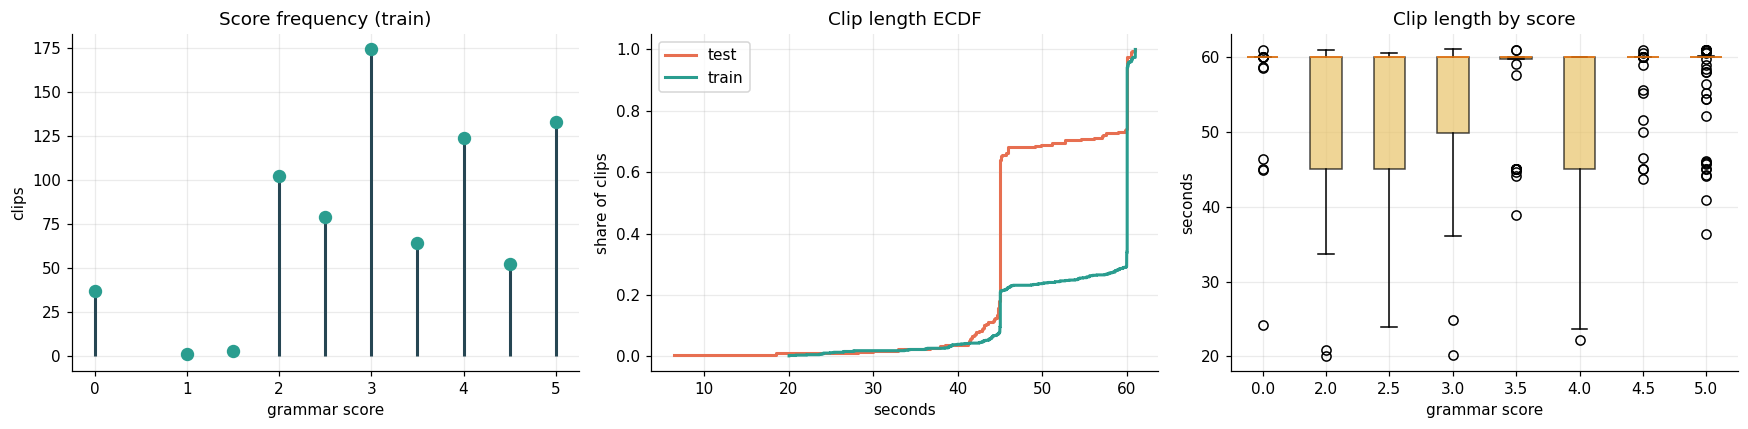

In [2]:
# Cell 2 | load data, build the master table, first look
require("locate_file", "PALETTE", "CACHE_DIR")

DATA_DIR = "/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final"
print(sorted(os.listdir(DATA_DIR)))
assert os.path.exists(f"{DATA_DIR}/train.csv"), "train.csv is not directly inside DATA_DIR, check the listing above"
train_df = pd.read_csv(f"{DATA_DIR}/train.csv")
test_df = pd.read_csv(f"{DATA_DIR}/test.csv")
sample_df = pd.read_csv(f"{DATA_DIR}/sample_submission.csv")

clips = pd.concat([train_df.assign(split="train"), test_df.assign(split="test", label=np.nan)], ignore_index=True)
clips = clips.rename(columns={"filename": "fname"})
# train and test reuse file names, so every row is keyed on split + name
clips["clip_key"] = clips["split"] + "/" + clips["fname"]
clips["audio_path"] = DATA_DIR + "/" + clips["clip_key"]
assert clips["clip_key"].is_unique
clips["seconds"] = [sf.info(p).duration for p in tqdm(clips["audio_path"], desc="durations")]

train_mask = (clips["split"] == "train").to_numpy()
train_pos = np.flatnonzero(train_mask)          # row positions of train clips in `clips`
test_pos = np.flatnonzero(~train_mask)          # row positions of test clips in `clips`
target = clips.loc[train_mask, "label"].to_numpy()

# score 0 is a "not a real answer" cluster, so it is kept out of modelling
nz_mask = target > 0
nz_pos = train_pos[nz_mask]                     # positions (in `clips`) of non-zero train clips
target_nz = target[nz_mask]

print("rows:", clips["split"].value_counts().to_dict())
print("score counts:", pd.Series(target).value_counts().sort_index().to_dict())
print("test.csv rows:", len(test_df), "| sample_submission rows:", len(sample_df),
      "| same columns:", list(test_df.columns[:1]) + ["label"] == list(sample_df.columns))

# ---- plots
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

counts = pd.Series(target).value_counts().sort_index()
axes[0].vlines(counts.index, 0, counts.values, color=PALETTE["accent"], lw=2)
axes[0].scatter(counts.index, counts.values, s=60, color=PALETTE["train"], zorder=3)
axes[0].set(title="Score frequency (train)", xlabel="grammar score", ylabel="clips")

for name, sub in clips.groupby("split"):
    xs = np.sort(sub["seconds"].to_numpy())
    axes[1].step(xs, np.arange(1, len(xs) + 1) / len(xs), where="post", label=name, color=PALETTE[name], lw=2)
axes[1].set(title="Clip length ECDF", xlabel="seconds", ylabel="share of clips")
axes[1].legend()

levels = [s for s, c in counts.items() if c >= 5]
axes[2].boxplot([clips.loc[train_mask, "seconds"].to_numpy()[target == s] for s in levels],
                labels=[str(s) for s in levels], patch_artist=True,
                boxprops={"facecolor": PALETTE["warn"], "alpha": 0.7})
axes[2].set(title="Clip length by score", xlabel="grammar score", ylabel="seconds")
plt.tight_layout()
plt.show()

## 3. Transcripts
Whisper large-v3 turns each clip into text. Fillers, pauses and word timings are kept because they are useful signals. The result is saved so this slow step runs once.

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 15.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 66.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.3/40.3 MB 55.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 80.5 MB/s eta 0:00:00


whisper:   0%|          | 0/985 [00:00<?, ?it/s]

36.5 min
[0] While pedaling, the wind boxed on my skin. every time I leave my home, I just make myself forget the truth so that it ever exists. into an a

[2] Once upon a time, we, with five friends, went on a tour, went on a deep tour with a travel agent on a Manali, and we stayed in a resort, and

[3] The playground is very, very beautiful and fun. There are- there are play-tools like the merry-go-round, the swing, the students usually enj

[5] The journey to Switzerland is an adventure in itself, whether you arrive by plane, train, or car. If you fly into Zurich or Genoa, you will 



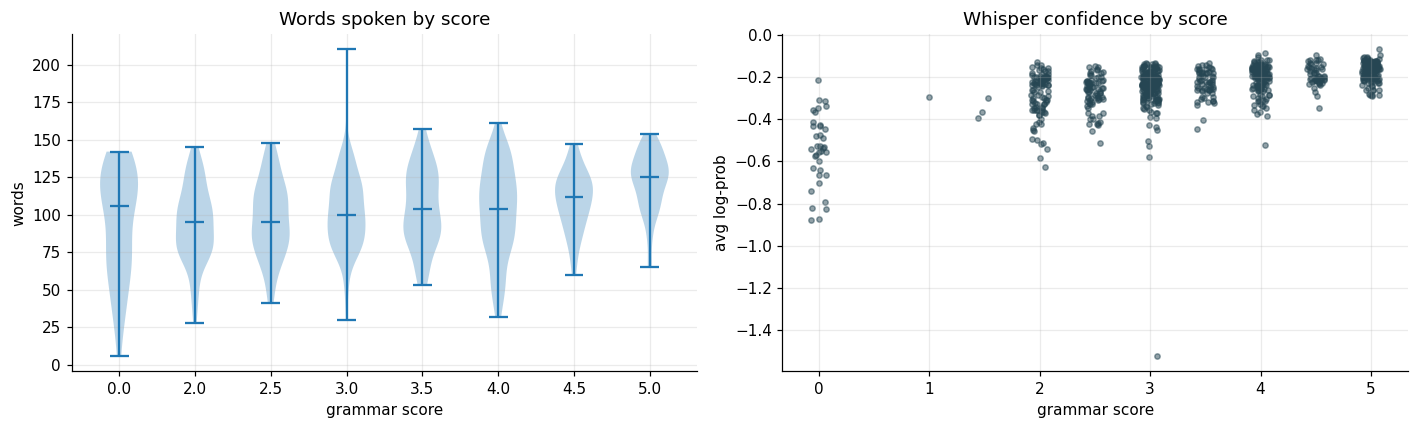

In [3]:
# Cell 3 | Whisper large-v3 transcripts (cached)
require("clips", "locate_file", "release_gpu", "PALETTE", "CACHE_DIR", "train_mask", "target")

TRANSCRIPT_FILE = "transcripts.parquet"
FILLER_PROMPT = "Umm, so, uh, I think... I mean, like, we was going there and- and then, hmm, yeah."

if locate_file(TRANSCRIPT_FILE) is None:
    try:
        import faster_whisper  # noqa: F401
    except ImportError:
        import subprocess, sys
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "faster-whisper==1.1.1"])
    from concurrent.futures import ThreadPoolExecutor
    from faster_whisper import WhisperModel

    asr = WhisperModel("large-v3", device="cuda", device_index=[0, 1], compute_type="float16", num_workers=2)

    def transcribe_clip(path):
        samples, _ = sf.read(path, dtype="float32")   # raw samples: pyav decoding breaks on Kaggle
        segs, _ = asr.transcribe(samples, language="en", beam_size=5, word_timestamps=True,
                                 condition_on_previous_text=False, initial_prompt=FILLER_PROMPT,
                                 vad_filter=False)
        segs = list(segs)
        words = [{"w": w.word, "s": round(w.start, 2), "e": round(w.end, 2), "p": round(w.probability, 3)}
                 for sg in segs for w in sg.words]
        return {
            "text": " ".join(sg.text.strip() for sg in segs),
            "avg_logprob": float(np.mean([sg.avg_logprob for sg in segs])) if segs else np.nan,
            "no_speech_prob": float(np.mean([sg.no_speech_prob for sg in segs])) if segs else np.nan,
            "words": json.dumps(words),
        }

    t0 = time.time()
    with ThreadPoolExecutor(2) as pool:
        rows = list(tqdm(pool.map(transcribe_clip, clips["audio_path"]), total=len(clips), desc="whisper"))
    print(f"{(time.time() - t0) / 60:.1f} min")
    pd.DataFrame(rows).assign(clip_key=clips["clip_key"].values).to_parquet(f"{CACHE_DIR}/{TRANSCRIPT_FILE}", index=False)
    del asr
    release_gpu()

tx = pd.read_parquet(locate_file(TRANSCRIPT_FILE))
# older caches were keyed on the bare file name, newer ones on split/name
key_col = "clip_key" if "clip_key" in tx.columns else "file_id"
ref_keys = clips["clip_key"] if key_col == "clip_key" else clips["fname"]
assert (tx[key_col].values == ref_keys.values).all(), "transcript cache is not aligned with clips"

clips = clips.drop(columns=[c for c in ("text", "avg_logprob", "no_speech_prob", "words") if c in clips.columns])
clips = pd.concat([clips, tx.drop(columns=key_col)], axis=1)
clips["text"] = clips["text"].fillna("")
clips["word_list"] = clips["words"].apply(json.loads)
clips["n_words"] = clips["text"].str.split().str.len()

for level in (0, 2, 3, 5):
    print(f"[{level}] {clips.loc[train_mask & (clips['label'] == level), 'text'].iloc[0][:140]}\n")

# ---- plots
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
lv = sorted(clips["label"].dropna().unique())
axes[0].violinplot([clips.loc[clips["label"] == s, "n_words"] for s in lv if (clips["label"] == s).sum() >= 5],
                   showmedians=True)
axes[0].set_xticks(range(1, len([s for s in lv if (clips["label"] == s).sum() >= 5]) + 1))
axes[0].set_xticklabels([str(s) for s in lv if (clips["label"] == s).sum() >= 5])
axes[0].set(title="Words spoken by score", xlabel="grammar score", ylabel="words")

jit = np.random.uniform(-0.08, 0.08, train_mask.sum())
axes[1].scatter(clips.loc[train_mask, "label"] + jit, clips.loc[train_mask, "avg_logprob"],
                s=12, alpha=0.5, color=PALETTE["accent"])
axes[1].set(title="Whisper confidence by score", xlabel="grammar score", ylabel="avg log-prob")
plt.tight_layout()
plt.show()

## 4. Fluency features
Simple numbers from the transcript: speaking speed, pauses, fillers, repeats, sentence length and vocabulary variety.

fluency:   0%|          | 0/985 [00:00<?, ?it/s]

(985, 21)


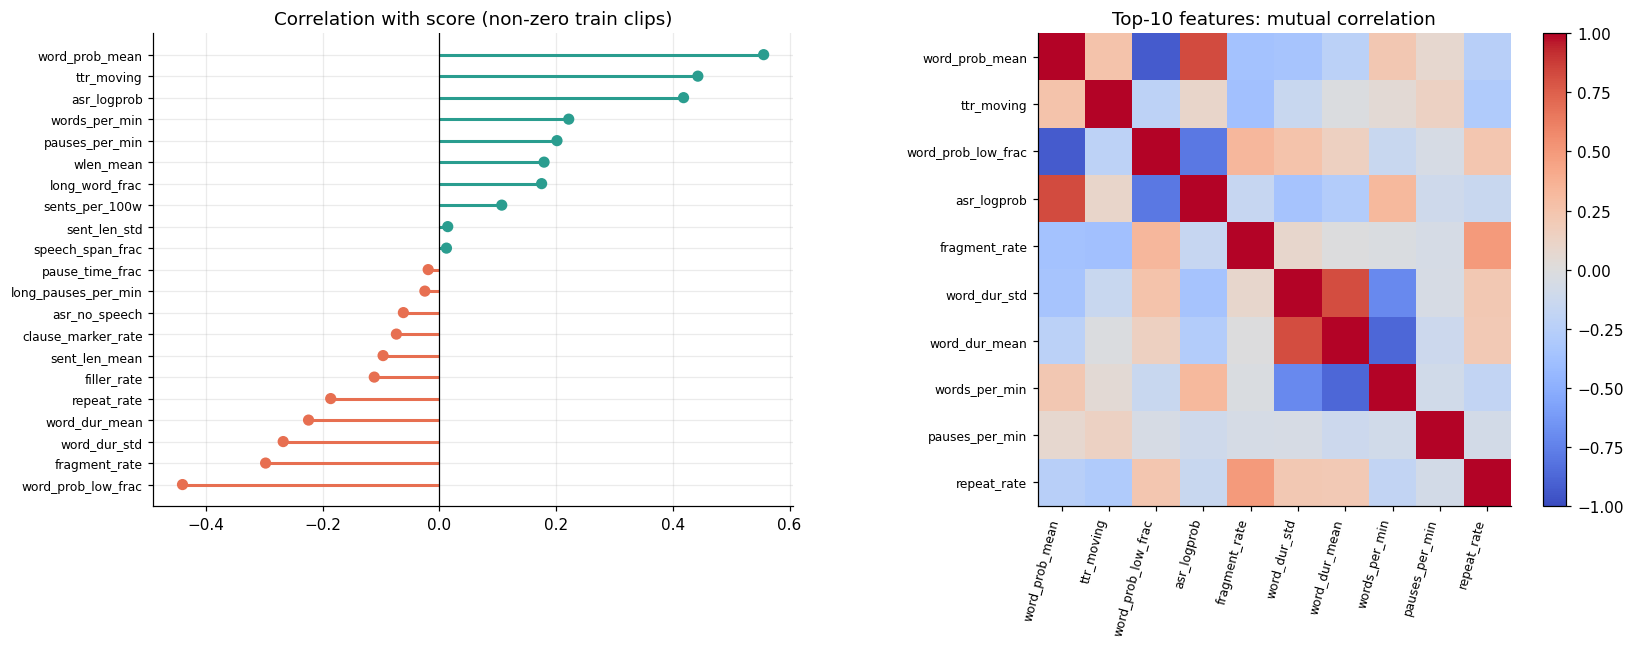

In [4]:
# Cell 4 | timing, disfluency and complexity features
require("clips", "PALETTE", "nz_pos", "target_nz")
assert "word_list" in clips.columns, "run Cell 3 first"

FILLER_WORDS = {"um", "umm", "uh", "uhm", "hmm", "mm", "er", "erm", "ah", "eh"}
CLAUSE_MARKERS = {"because", "although", "though", "while", "whereas", "unless", "since", "which", "who",
                  "whom", "whose", "that", "when", "if", "whether", "where", "after", "before"}


def word_tokens(text):
    return re.findall(r"[a-z']+", text.lower())


def split_sentences(text):
    return [s for s in re.split(r"(?<=[.!?])\s+", text.strip()) if s]


def moving_ttr(tokens, window=50):
    if len(tokens) <= window:
        return len(set(tokens)) / max(len(tokens), 1)
    return float(np.mean([len(set(tokens[i:i + window])) / window for i in range(len(tokens) - window + 1)]))


def speech_stats(row):
    timed, toks = row.word_list, word_tokens(row.text)
    content = [t for t in toks if t not in FILLER_WORDS]
    n_tok = max(len(toks), 1)
    out = {}
    if len(timed) > 1:
        t_start = np.array([w["s"] for w in timed])
        t_end = np.array([w["e"] for w in timed])
        span = max(t_end[-1] - t_start[0], 1.0)
        gaps = np.clip(t_start[1:] - t_end[:-1], 0, None)
        dur = t_end - t_start
        out["words_per_min"] = 60 * len(timed) / span
        out["pauses_per_min"] = 60 * (gaps > 0.5).sum() / span
        out["long_pauses_per_min"] = 60 * (gaps > 1.5).sum() / span
        out["pause_time_frac"] = gaps[gaps > 0.3].sum() / span
        out["word_dur_mean"] = float(dur.mean())
        out["word_dur_std"] = float(dur.std())
        out["speech_span_frac"] = span / row.seconds
    probs = np.array([w["p"] for w in timed]) if timed else np.array([0.0])
    out["word_prob_mean"] = probs.mean()
    out["word_prob_low_frac"] = (probs < 0.5).mean()
    out["filler_rate"] = sum(t in FILLER_WORDS for t in toks) / n_tok
    out["fragment_rate"] = len(re.findall(r"\b[\w']+-(?=\s|$)", row.text)) / n_tok
    out["repeat_rate"] = sum(a == b for a, b in zip(content, content[1:])) / n_tok
    sent_len = [len(word_tokens(s)) for s in split_sentences(row.text)] or [0]
    out["sent_len_mean"] = np.mean(sent_len)
    out["sent_len_std"] = np.std(sent_len)
    out["sents_per_100w"] = 100 * len(sent_len) / n_tok
    out["ttr_moving"] = moving_ttr(content)
    out["wlen_mean"] = np.mean([len(t) for t in content]) if content else 0
    out["long_word_frac"] = np.mean([len(t) > 6 for t in content]) if content else 0
    out["clause_marker_rate"] = sum(t in CLAUSE_MARKERS for t in content) / n_tok
    out["asr_logprob"] = row.avg_logprob
    out["asr_no_speech"] = row.no_speech_prob
    return out


fluency_feats = pd.DataFrame([speech_stats(r) for r in tqdm(clips.itertuples(), total=len(clips), desc="fluency")]).fillna(0)
print(fluency_feats.shape)


def corr_lollipop(ax, table, title, top=None):
    r = table.loc[nz_pos].corrwith(pd.Series(target_nz, index=nz_pos)).dropna().sort_values()
    if top:
        r = r.iloc[np.argsort(-np.abs(r.values))[:top]].sort_values()
    colors = [PALETTE["train"] if v >= 0 else PALETTE["test"] for v in r.values]
    ax.hlines(range(len(r)), 0, r.values, color=colors, lw=2)
    ax.scatter(r.values, range(len(r)), color=colors, s=40, zorder=3)
    ax.set_yticks(range(len(r)))
    ax.set_yticklabels(r.index, fontsize=8)
    ax.axvline(0, color="k", lw=0.8)
    ax.set_title(title)
    return r


fig, axes = plt.subplots(1, 2, figsize=(15, 6))
r_fl = corr_lollipop(axes[0], fluency_feats, "Correlation with score (non-zero train clips)")
top_cols = list(r_fl.index[np.argsort(-np.abs(r_fl.values))[:10]])
cm = fluency_feats.loc[nz_pos, top_cols].corr().to_numpy()
im = axes[1].imshow(cm, cmap="coolwarm", vmin=-1, vmax=1)
axes[1].set_xticks(range(len(top_cols)))
axes[1].set_xticklabels(top_cols, rotation=75, ha="right", fontsize=8)
axes[1].set_yticks(range(len(top_cols)))
axes[1].set_yticklabels(top_cols, fontsize=8)
axes[1].grid(False)
axes[1].set_title("Top-10 features: mutual correlation")
plt.colorbar(im, ax=axes[1], fraction=0.046)
plt.tight_layout()
plt.show()

## 5. Language-model features
A small local model (Qwen2.5-1.5B) measures how surprising each word is. Grammatical text is usually less surprising. It is free and needs no API key.

config.json:   0%|          | 0.00/684 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

qwen:   0%|          | 0/985 [00:00<?, ?it/s]

lm_feats (985, 7) | lm_emb (985, 2, 1536)


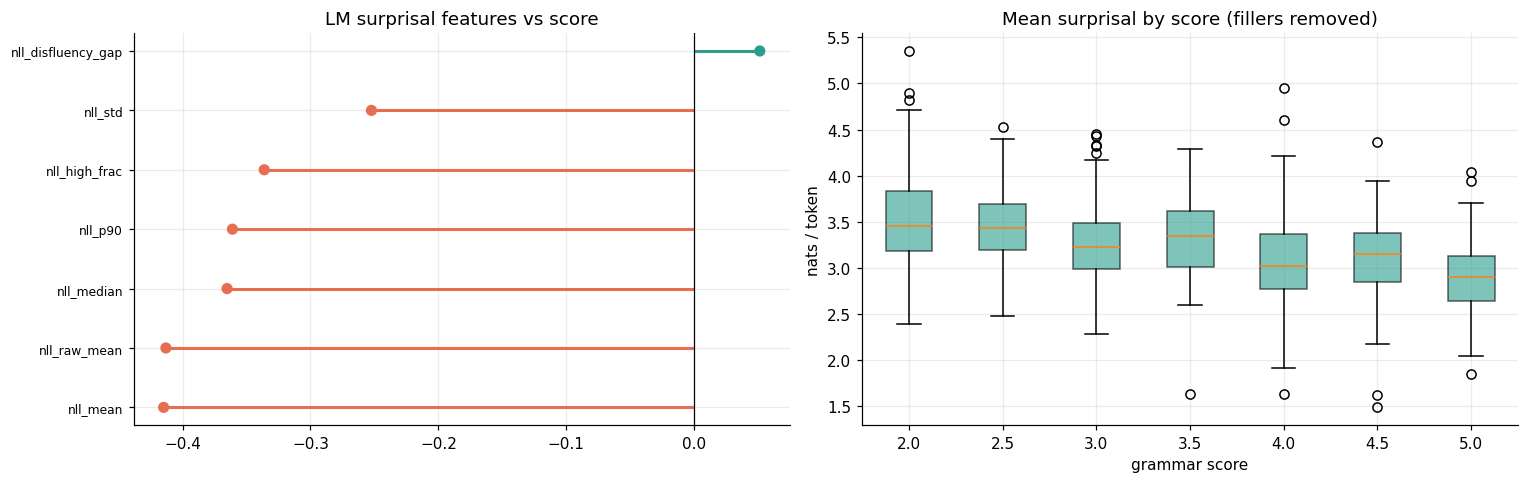

In [5]:
# Cell 5 | free local language-model features, replaces the paid API grading
require("clips", "locate_file", "release_gpu", "PALETTE", "CACHE_DIR", "FILLER_WORDS",
        "corr_lollipop", "nz_pos", "target_nz")

LM_ID = "Qwen/Qwen2.5-1.5B"
LM_DTYPE = torch.float16                  # switch to torch.float32 if the finite check below fails
LM_LAYERS = (16, 22)                      # mid / upper layers carry the most syntax information
STATS_FILE, EMB_FILE = "qwen_nll_stats.parquet", "qwen_emb.npy"


def strip_disfluency(text):
    text = re.sub(r"\b[\w']+-(?=\s|$)", " ", text)                                   # cut-off fragments like "pl-"
    text = re.sub(r"\b(" + "|".join(sorted(FILLER_WORDS)) + r")\b", " ", text, flags=re.I)
    return re.sub(r"\s+", " ", text).strip()


if locate_file(STATS_FILE) is None or locate_file(EMB_FILE) is None:
    from transformers import AutoModelForCausalLM, AutoTokenizer

    tok = AutoTokenizer.from_pretrained(LM_ID)
    lm = AutoModelForCausalLM.from_pretrained(LM_ID, torch_dtype=LM_DTYPE).to("cuda:0").eval()

    @torch.no_grad()
    def token_nll(text, want_hidden=False):
        ids = tok(text, return_tensors="pt", truncation=True, max_length=600).input_ids[0]
        ids = torch.cat([torch.tensor([tok.eos_token_id]), ids]).unsqueeze(0).to("cuda:0")   # eos acts as start token
        out = lm(ids, output_hidden_states=want_hidden)
        logp = torch.log_softmax(out.logits[0, :-1].float(), -1)
        nll = -logp.gather(1, ids[0, 1:, None]).squeeze(1).cpu().numpy()
        hid = None
        if want_hidden:
            hid = np.stack([out.hidden_states[l][0, 1:].float().mean(0).cpu().numpy() for l in LM_LAYERS])
        return nll, hid

    stat_rows, emb_rows = [], []
    for text in tqdm(clips["text"], desc="qwen"):
        raw = text if text.strip() else "."
        clean = strip_disfluency(text) or "."
        nll_c, hid = token_nll(clean, want_hidden=True)
        nll_r, _ = token_nll(raw)
        stat_rows.append({
            "nll_mean": nll_c.mean(), "nll_median": np.median(nll_c), "nll_std": nll_c.std(),
            "nll_p90": np.percentile(nll_c, 90), "nll_high_frac": (nll_c > 7).mean(),
            "nll_raw_mean": nll_r.mean(), "nll_disfluency_gap": nll_r.mean() - nll_c.mean(),
        })
        emb_rows.append(hid)

    stats_new = pd.DataFrame(stat_rows)
    emb_new = np.stack(emb_rows).astype(np.float32)
    # check before saving so a bad run never lands in the cache
    assert np.isfinite(stats_new.to_numpy()).all() and np.isfinite(emb_new).all(), \
        "NaN/inf in LM features: set LM_DTYPE = torch.float32 and rerun this cell"
    stats_new.assign(clip_key=clips["clip_key"].values).to_parquet(f"{CACHE_DIR}/{STATS_FILE}", index=False)
    np.save(f"{CACHE_DIR}/{EMB_FILE}", emb_new.astype(np.float16))
    del lm
    release_gpu()

_stats = pd.read_parquet(locate_file(STATS_FILE))
assert (_stats["clip_key"].values == clips["clip_key"].values).all(), "LM cache is not aligned with clips"
lm_feats = _stats.drop(columns="clip_key").reset_index(drop=True)
lm_emb = np.load(locate_file(EMB_FILE)).astype(np.float32)          # (clips, len(LM_LAYERS), hidden)
assert len(lm_feats) == len(lm_emb) == len(clips)
assert np.isfinite(lm_feats.to_numpy()).all() and np.isfinite(lm_emb).all(), "cached LM features contain NaN/inf"
print("lm_feats", lm_feats.shape, "| lm_emb", lm_emb.shape)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
corr_lollipop(axes[0], lm_feats, "LM surprisal features vs score")
lv = [s for s in sorted(set(target_nz)) if (target_nz == s).sum() >= 5]
axes[1].boxplot([lm_feats.loc[nz_pos, "nll_mean"].to_numpy()[target_nz == s] for s in lv],
                labels=[str(s) for s in lv], patch_artist=True,
                boxprops={"facecolor": PALETTE["train"], "alpha": 0.6})
axes[1].set(title="Mean surprisal by score (fillers removed)", xlabel="grammar score", ylabel="nats / token")
plt.tight_layout()
plt.show()

## 6. Audio embeddings
WavLM, HuBERT and the Whisper encoder turn each clip's audio into numbers. Results are saved after the first run.

In [6]:
# Cell 6 | audio embeddings from WavLM, HuBERT and the Whisper encoder (cached)
require("clips", "locate_file", "release_gpu", "CACHE_DIR")

FRAME_STRIDE, FRAME_CAP = 8, 400                       # frame heads see blocks of 8 frames (~160 ms), max 400 blocks
HEAD_LAYERS = {"hubert": [18], "wavlm": [18], "whisper": [28, 31]}
frames_needed = any(
    locate_file(f"head_{t}{l}_{part}.npy") is None
    for t, ls in HEAD_LAYERS.items() for l in ls for part in ("oof", "test")
)
print("frame sequences needed for heads:", frames_needed)

_sr = sf.info(clips["audio_path"].iloc[0]).samplerate
if _sr != 16000:
    print(f"WARNING: first clip is {_sr} Hz, the extractors below assume 16 kHz")


def read_mono(path):
    audio, _ = sf.read(path, dtype="float32")
    return audio.mean(1) if audio.ndim > 1 else audio


def summarise_layers(hidden, keep):
    """hidden: list of (1, T, D) tensors, one per layer -> per-layer mean/std and optional block-averaged frames."""
    mean = torch.stack([h[0].float().mean(0) for h in hidden]).cpu().numpy()
    std = torch.stack([h[0].float().std(0) for h in hidden]).cpu().numpy()
    seqs = {}
    for l in keep:
        x = hidden[l][0].float()
        T = (x.shape[0] // FRAME_STRIDE) * FRAME_STRIDE
        blocks = x[:T].reshape(T // FRAME_STRIDE, FRAME_STRIDE, -1).mean(1) if T >= FRAME_STRIDE else x.mean(0, keepdim=True)
        seqs[l] = blocks[:FRAME_CAP].half().cpu().numpy()
    return mean, std, seqs


def save_pooled(tag, means, stds):
    np.save(f"{CACHE_DIR}/{tag}_mean.npy", np.stack(means).astype(np.float16))
    np.save(f"{CACHE_DIR}/{tag}_std.npy", np.stack(stds).astype(np.float16))


def extract_ssl(model_id, model_cls, keep, tag):
    from transformers import AutoFeatureExtractor, Wav2Vec2FeatureExtractor
    try:
        fx = AutoFeatureExtractor.from_pretrained(model_id)
    except Exception:
        fx = Wav2Vec2FeatureExtractor(sampling_rate=16000, do_normalize=True)
    net = model_cls.from_pretrained(model_id).to("cuda").eval()
    means, stds, seqs = [], [], {l: [] for l in keep}
    for path in tqdm(clips["audio_path"], desc=tag):
        x = fx(read_mono(path), sampling_rate=16000, return_tensors="pt").input_values.to("cuda")
        with torch.no_grad():
            hidden = net(x, output_hidden_states=True).hidden_states
        m, s, sq = summarise_layers(hidden, keep)
        means.append(m)
        stds.append(s)
        for l in keep:
            seqs[l].append(sq[l])
    save_pooled(tag, means, stds)
    del net
    release_gpu()
    return seqs


def extract_whisper(keep, tag="whisper"):
    from transformers import WhisperFeatureExtractor, WhisperModel
    fx = WhisperFeatureExtractor.from_pretrained("openai/whisper-large-v3")
    enc = WhisperModel.from_pretrained("openai/whisper-large-v3").encoder.half().cuda().eval()
    win = 30 * 16000
    means, stds, seqs = [], [], {l: [] for l in keep}
    for path in tqdm(clips["audio_path"], desc=tag):
        audio = read_mono(path)
        per_window = []
        for start in range(0, len(audio), win):
            chunk = audio[start:start + win]
            n_valid = max(1, int(len(chunk) / 16000 * 50))        # encoder runs at 50 frames/s, the rest is padding
            feats = fx(chunk, sampling_rate=16000, return_tensors="pt").input_features.half().cuda()
            with torch.no_grad():
                hidden = enc(feats, output_hidden_states=True).hidden_states
            per_window.append([h[0, :n_valid].float().cpu() for h in hidden])
        hidden = [torch.cat([w[l] for w in per_window]).unsqueeze(0) for l in range(len(per_window[0]))]
        m, s, sq = summarise_layers(hidden, keep)
        means.append(m)
        stds.append(s)
        for l in keep:
            seqs[l].append(sq[l])
    save_pooled(tag, means, stds)
    del enc
    release_gpu()
    return seqs


from transformers import HubertModel, WavLMModel

EXTRACTORS = {
    "wavlm": lambda keep: extract_ssl("microsoft/wavlm-large", WavLMModel, keep, "wavlm"),
    "whisper": lambda keep: extract_whisper(keep),
    "hubert": lambda keep: extract_ssl("facebook/hubert-large-ll60k", HubertModel, keep, "hubert"),
}

frame_store = {}                                       # (model, layer) -> list of (T, D) arrays, only filled if heads must be trained
for tag, extractor in EXTRACTORS.items():
    pooled_cached = locate_file(f"{tag}_mean.npy") is not None and locate_file(f"{tag}_std.npy") is not None
    want_frames = frames_needed and tag in HEAD_LAYERS
    if pooled_cached and not want_frames:
        continue
    seqs = extractor(HEAD_LAYERS[tag] if want_frames else [])
    frame_store.update({(tag, l): v for l, v in seqs.items()})

emb = {}
for tag in EXTRACTORS:
    for stat in ("mean", "std"):
        emb[f"{tag}_{stat}"] = np.load(locate_file(f"{tag}_{stat}.npy")).astype(np.float32)
for k, v in emb.items():
    assert v.shape[0] == len(clips) and np.isfinite(v).all(), f"{k} is misaligned or has NaN/inf"
print({k: v.shape for k, v in emb.items()})

frame sequences needed for heads: True


preprocessor_config.json:   0%|          | 0.00/214 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/2.22k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.26GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

...

Loading weights:   0%|          | 0/422 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.26GB            

model.safetensors: downloading bytes:           |  0.00B            

hubert:   0%|          | 0/985 [00:00<?, ?it/s]

{'wavlm_mean': (985, 25, 1024), 'wavlm_std': (985, 25, 1024), 'whisper_mean': (985, 33, 1280), 'whisper_std': (985, 33, 1280), 'hubert_mean': (985, 25, 1024), 'hubert_std': (985, 25, 1024)}


## 7. Speaker groups and folds
The same speakers appear many times in training, but the test speakers are new. So we group clips by speaker and make sure no speaker is on both sides of a split.

speaker groups: 413 | clips in groups of 2+: 549 | largest group: 37
within-group score std: 0.167  overall: 1.238
score-0 clips in one group: 37/37 | test clips close to it: 0
fold check passed: no speaker is shared between fit and validation


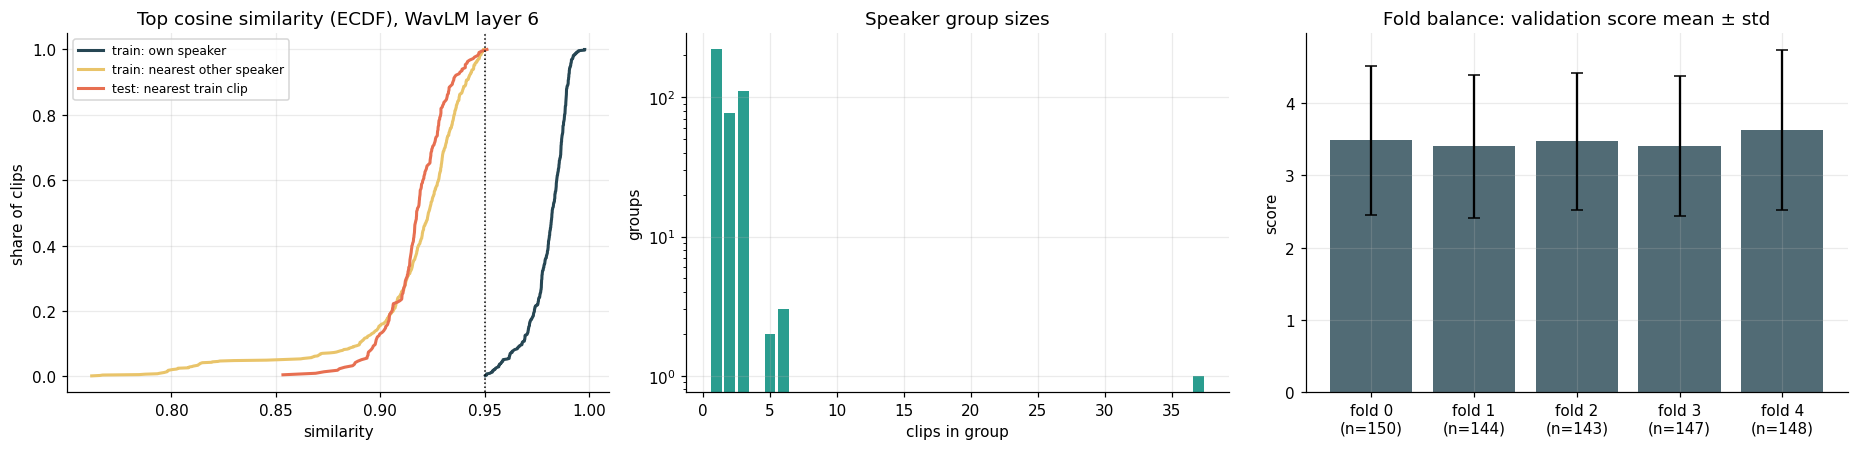

In [7]:
# Cell 7 | speaker groups from a voice-sensitive layer, and speaker-aware folds
require("clips", "emb", "train_pos", "test_pos", "target", "nz_mask", "target_nz", "PALETTE")
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import normalize

SAME_SPEAKER_SIM = 0.95
voice = normalize(emb["wavlm_mean"][:, 6])             # WavLM layer 6 mostly carries voice / channel information
sim_tr = voice[train_pos] @ voice[train_pos].T
np.fill_diagonal(sim_tr, 0)
n_groups, train_groups = connected_components(sim_tr > SAME_SPEAKER_SIM, directed=False)
group_size = np.bincount(train_groups)

same = train_groups[:, None] == train_groups[None, :]
sim_own = np.where(same, sim_tr, -1).max(1)
sim_other = np.where(~same, sim_tr, -1).max(1)
sim_test = (voice[test_pos] @ voice[train_pos].T).max(1)
in_multi = group_size[train_groups] > 1

print(f"speaker groups: {n_groups} | clips in groups of 2+: {in_multi.sum()} | largest group: {group_size.max()}")
within_std = np.mean([target[train_groups == g].std() for g in np.where(group_size > 1)[0]])
print(f"within-group score std: {within_std:.3f}  overall: {target.std():.3f}")

zero_group = np.bincount(train_groups[target == 0]).argmax()
print(f"score-0 clips in one group: {(train_groups[target == 0] == zero_group).sum()}/{(target == 0).sum()} | "
      f"test clips close to it: {((voice[test_pos] @ voice[train_pos][train_groups == zero_group].T).max(1) > SAME_SPEAKER_SIM).sum()}")

# ---- folds on the non-zero clips, grouped by speaker
groups_nz = train_groups[nz_mask]
strata_nz = (target_nz * 2).astype(int)


def make_folds(seed, k=5):
    splitter = StratifiedGroupKFold(k, shuffle=True, random_state=seed)
    return list(splitter.split(np.zeros(len(target_nz)), strata_nz, groups_nz))


for seed in range(5):                                  # no speaker may appear on both sides of any split
    for fit, val in make_folds(seed):
        assert not set(groups_nz[fit]) & set(groups_nz[val]), f"speaker leak in seed {seed}"
print("fold check passed: no speaker is shared between fit and validation")

# ---- plots
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for vals, name, col in [(sim_own[in_multi], "train: own speaker", PALETTE["accent"]),
                        (sim_other, "train: nearest other speaker", PALETTE["warn"]),
                        (sim_test, "test: nearest train clip", PALETTE["test"])]:
    xs = np.sort(vals)
    axes[0].plot(xs, np.arange(1, len(xs) + 1) / len(xs), label=name, color=col, lw=2)
axes[0].axvline(SAME_SPEAKER_SIM, color="k", ls=":", lw=1)
axes[0].set(title="Top cosine similarity (ECDF), WavLM layer 6", xlabel="similarity", ylabel="share of clips")
axes[0].legend(fontsize=8)

axes[1].bar(*np.unique(group_size, return_counts=True), color=PALETTE["train"])
axes[1].set(title="Speaker group sizes", xlabel="clips in group", ylabel="groups", yscale="log")

fold_stats = np.array([[target_nz[val].mean(), target_nz[val].std(), len(val)] for _, val in make_folds(0)])
axes[2].bar(range(5), fold_stats[:, 0], yerr=fold_stats[:, 1], color=PALETTE["accent"], alpha=0.8, capsize=4)
axes[2].set_xticks(range(5))
axes[2].set_xticklabels([f"fold {i}\n(n={int(n)})" for i, n in enumerate(fold_stats[:, 2])])
axes[2].set(title="Fold balance: validation score mean ± std", ylabel="score")
plt.tight_layout()
plt.show()

## 8. Attention heads
Small networks that look at the audio frame by frame and learn which moments matter. They are weaker than the simpler models.

head_hubert18    speaker-fold RMSE 0.6704   r 0.750
head_wavlm18     speaker-fold RMSE 0.6146   r 0.796
head_whisper28   speaker-fold RMSE 0.8668   r 0.823
head_whisper31   speaker-fold RMSE 0.6693   r 0.828


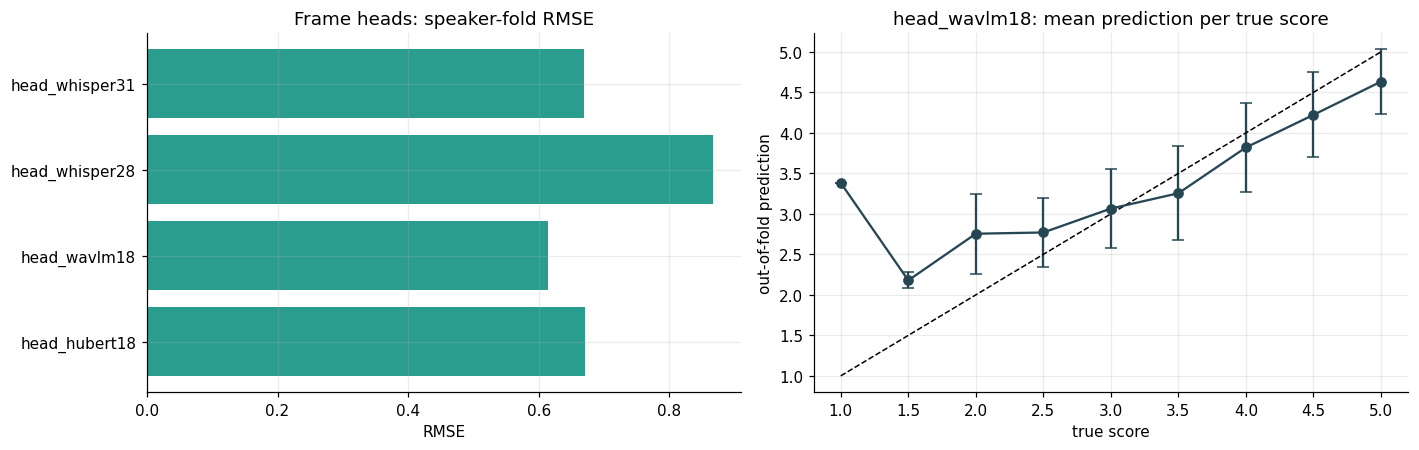

In [8]:
# Cell 8 | attention-pooling heads on frame sequences (cached)
require("clips", "locate_file", "CACHE_DIR", "HEAD_LAYERS", "frame_store", "make_folds",
        "nz_pos", "test_pos", "target_nz", "root_mse", "PALETTE")
import torch.nn as nn
import torch.nn.functional as F
from scipy.stats import pearsonr

T_MU, T_SD = target_nz.mean(), target_nz.std()
HEAD_SEEDS = (0, 1, 2)
HEAD_EPOCHS = 30


class AttnPoolHead(nn.Module):
    """layer norm -> learned attention pooling + mean + std pooling -> small MLP."""
    def __init__(self, d, hidden=192, drop=0.3):
        super().__init__()
        self.norm = nn.LayerNorm(d)
        self.score = nn.Sequential(nn.Linear(d, 128), nn.Tanh(), nn.Linear(128, 1))
        self.mlp = nn.Sequential(nn.Dropout(drop), nn.Linear(3 * d, hidden), nn.GELU(), nn.Dropout(drop), nn.Linear(hidden, 1))

    def forward(self, x, mask):
        x = self.norm(x)
        w = self.score(x).squeeze(-1).masked_fill(~mask, -1e4).softmax(1)
        attended = (w.unsqueeze(-1) * x).sum(1)
        m = mask.unsqueeze(-1).float()
        n = m.sum(1).clamp(min=1)
        mean = (x * m).sum(1) / n
        std = (((x - mean.unsqueeze(1)) ** 2 * m).sum(1) / n).clamp(min=1e-6).sqrt()
        return self.mlp(torch.cat([attended, mean, std], -1)).squeeze(-1)


def pad_sequences(seqs):
    T = max(s.shape[0] for s in seqs)
    X = np.zeros((len(seqs), T, seqs[0].shape[1]), np.float16)
    M = np.zeros((len(seqs), T), bool)
    for i, s in enumerate(seqs):
        X[i, :s.shape[0]] = s
        M[i, :s.shape[0]] = True
    return torch.tensor(X), torch.tensor(M)


def fit_head(X, M, t, fit_pos, seed, epochs=HEAD_EPOCHS, bs=32, lr=1e-3):
    # fixed schedule: the validation fold is never used to pick an epoch, so the out-of-fold scores stay honest
    torch.manual_seed(seed)
    net = AttnPoolHead(X.shape[-1]).cuda()
    opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=0.05)
    steps = epochs * int(np.ceil(len(fit_pos) / bs))
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=steps)
    for ep in range(epochs):
        net.train()
        order = np.random.RandomState(seed * 100 + ep).permutation(fit_pos)
        for i in range(0, len(order), bs):
            b = order[i:i + bs]
            xb, mb = X[b].cuda().float(), M[b].cuda()
            xb = xb + 0.1 * torch.randn_like(xb) * xb.std()           # light feature noise
            loss = F.mse_loss(net(xb, mb), t[b].cuda())
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            opt.step()
            sched.step()
    return net.eval()


@torch.no_grad()
def head_predict(net, X, M, pos):
    out = [net(X[pos[i:i + 64]].cuda().float(), M[pos[i:i + 64]].cuda()) for i in range(0, len(pos), 64)]
    return torch.cat(out).cpu().numpy()


head_oof, head_test = {}, {}
for tag, layers in HEAD_LAYERS.items():
    for l in layers:
        name = f"head_{tag}{l}"
        f_oof, f_te = f"{name}_oof.npy", f"{name}_test.npy"
        if locate_file(f_oof) is None or locate_file(f_te) is None:
            assert (tag, l) in frame_store, f"no frame sequences for {tag} layer {l}: rerun Cell 6"
            X, M = pad_sequences(frame_store[(tag, l)])
            t = torch.tensor(((clips["label"].fillna(T_MU).to_numpy() - T_MU) / T_SD).astype(np.float32))
            oof, te = np.zeros(len(target_nz)), np.zeros(len(test_pos))
            for seed in HEAD_SEEDS:
                for fit, val in make_folds(seed):
                    net = fit_head(X, M, t, nz_pos[fit], seed)
                    oof[val] += head_predict(net, X, M, nz_pos[val]) / len(HEAD_SEEDS)
                    te += head_predict(net, X, M, test_pos) / (5 * len(HEAD_SEEDS))
                    del net
            np.save(f"{CACHE_DIR}/{f_oof}", oof * T_SD + T_MU)
            np.save(f"{CACHE_DIR}/{f_te}", te * T_SD + T_MU)
            del X, M
            release_gpu()
        head_oof[name], head_test[name] = np.load(locate_file(f_oof)), np.load(locate_file(f_te))
        assert head_oof[name].shape == (len(target_nz),) and head_test[name].shape == (len(test_pos),), f"{name}: bad cache shape"
        print(f"{name:16s} speaker-fold RMSE {root_mse(target_nz, head_oof[name]):.4f}   r {pearsonr(target_nz, head_oof[name])[0]:.3f}")

frame_store.clear()
gc.collect()

# ---- plots
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
names = list(head_oof)
rm = [root_mse(target_nz, head_oof[n]) for n in names]
axes[0].barh(names, rm, color=PALETTE["train"])
axes[0].set(title="Frame heads: speaker-fold RMSE", xlabel="RMSE")

best = names[int(np.argmin(rm))]
levels = sorted(set(target_nz))
mu = [head_oof[best][target_nz == s].mean() for s in levels]
sd = [head_oof[best][target_nz == s].std() for s in levels]
axes[1].errorbar(levels, mu, yerr=sd, fmt="o-", color=PALETTE["accent"], capsize=4)
axes[1].plot([min(levels), max(levels)], [min(levels), max(levels)], "k--", lw=1)
axes[1].set(title=f"{best}: mean prediction per true score", xlabel="true score", ylabel="out-of-fold prediction")
plt.tight_layout()
plt.show()

## 9. Base models
One simple model (ridge or kernel ridge) per feature group, each scored on unseen speakers.

ridge_wavlm18        speaker-fold RMSE 0.5853   r 0.817
ridge_wavlm_allL     speaker-fold RMSE 0.5915   r 0.813
ridge_wavlm_std19    speaker-fold RMSE 0.5955   r 0.810
krr_whisper31        speaker-fold RMSE 0.5744   r 0.825
ridge_whisper_std32  speaker-fold RMSE 0.5890   r 0.815
ridge_hubert22       speaker-fold RMSE 0.6119   r 0.797
ridge_hubert22_ms    speaker-fold RMSE 0.6009   r 0.805
ridge_text_tab       speaker-fold RMSE 0.7443   r 0.681
ridge_qwen_mid       speaker-fold RMSE 0.6196   r 0.792
ridge_qwen_top       speaker-fold RMSE 0.6220   r 0.790


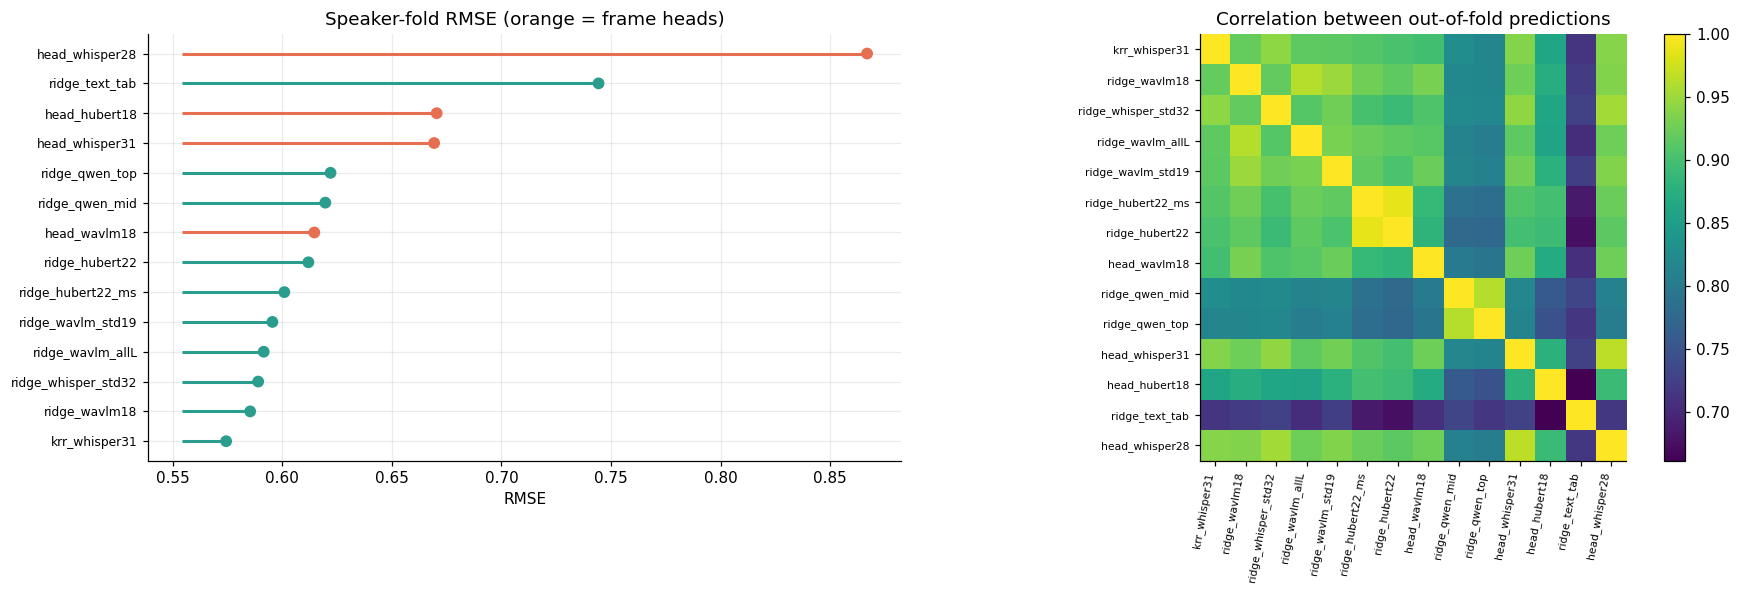

In [9]:
# Cell 9 | one small model per feature group, scored with speaker folds
require("emb", "fluency_feats", "lm_feats", "lm_emb", "make_folds", "nz_pos", "test_pos",
        "target_nz", "root_mse", "head_oof", "head_test", "PALETTE")
from scipy.stats import pearsonr
from sklearn.kernel_ridge import KernelRidge
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

BASE_SEEDS = (0, 1, 2, 3, 4)


def cv_predict(make_model, X, seeds=BASE_SEEDS):
    """Out-of-fold predictions on non-zero train clips (averaged over fold seeds) and averaged test predictions."""
    X_nz, X_te = X[nz_pos], X[test_pos]
    oof, te = np.zeros(len(target_nz)), np.zeros(len(test_pos))
    for seed in seeds:
        for fit, val in make_folds(seed):
            m = make_model().fit(X_nz[fit], target_nz[fit])
            oof[val] += m.predict(X_nz[val]) / len(seeds)
            te += m.predict(X_te) / (5 * len(seeds))
    return oof, te


make_ridge = lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-1, 6, 30)))
make_krr = lambda gamma: (lambda: make_pipeline(StandardScaler(), KernelRidge(alpha=0.3, kernel="rbf", gamma=gamma)))

W, WH, HB = emb["wavlm_mean"], emb["whisper_mean"], emb["hubert_mean"]
tab_all = pd.concat([fluency_feats, lm_feats], axis=1).to_numpy(np.float32)

base_specs = {
    "ridge_wavlm18":        (make_ridge, W[:, 18]),
    "ridge_wavlm_allL":     (make_ridge, W.reshape(len(W), -1)),
    "ridge_wavlm_std19":    (make_ridge, emb["wavlm_std"][:, 19]),
    "krr_whisper31":        (make_krr(0.3 / 1280), WH[:, 31]),
    "ridge_whisper_std32":  (make_ridge, emb["whisper_std"][:, 32]),
    "ridge_hubert22":       (make_ridge, HB[:, 22]),
    "ridge_hubert22_ms":    (make_ridge, np.hstack([HB[:, 22], emb["hubert_std"][:, 22]])),
    "ridge_text_tab":       (make_ridge, tab_all),                  # fluency stats + Qwen surprisal stats
    "ridge_qwen_mid":       (make_ridge, lm_emb[:, 0]),             # Qwen hidden state, first of LM_LAYERS
    "ridge_qwen_top":       (make_ridge, lm_emb[:, 1]),             # Qwen hidden state, second of LM_LAYERS
}

oof_store, test_store = dict(head_oof), dict(head_test)
for name, (maker, X) in base_specs.items():
    X = np.asarray(X, dtype=np.float32)
    assert X.shape[0] == len(clips) and np.isfinite(X).all(), f"{name}: bad feature matrix"
    oof_store[name], test_store[name] = cv_predict(maker, X)
    print(f"{name:20s} speaker-fold RMSE {root_mse(target_nz, oof_store[name]):.4f}   r {pearsonr(target_nz, oof_store[name])[0]:.3f}")

# ---- plots
names = list(oof_store)
rm = pd.Series({n: root_mse(target_nz, oof_store[n]) for n in names}).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
colors = [PALETTE["test"] if n.startswith("head_") else PALETTE["train"] for n in rm.index]
axes[0].hlines(range(len(rm)), rm.min() - 0.02, rm.values, color=colors, lw=2)
axes[0].scatter(rm.values, range(len(rm)), color=colors, s=45, zorder=3)
axes[0].set_yticks(range(len(rm)))
axes[0].set_yticklabels(rm.index, fontsize=8)
axes[0].set(title="Speaker-fold RMSE (orange = frame heads)", xlabel="RMSE")

order = list(rm.index)
cm = np.corrcoef(np.column_stack([oof_store[n] for n in order]).T)
im = axes[1].imshow(cm, cmap="viridis", vmin=cm.min(), vmax=1)
axes[1].set_xticks(range(len(order)))
axes[1].set_xticklabels(order, rotation=80, ha="right", fontsize=7)
axes[1].set_yticks(range(len(order)))
axes[1].set_yticklabels(order, fontsize=7)
axes[1].grid(False)
axes[1].set_title("Correlation between out-of-fold predictions")
plt.colorbar(im, ax=axes[1], fraction=0.046)
plt.tight_layout()
plt.show()

## 10. Blend
Combine all model predictions into one score and keep it between 1 and 5. The training RMSE is printed here: in-sample, and out-of-fold on unseen speakers.

In [10]:
# Cell 10 | blend the out-of-fold predictions
require("oof_store", "test_store", "base_specs", "make_folds", "target_nz", "nz_pos", "root_mse", "PALETTE")
from scipy.optimize import minimize
from scipy.stats import pearsonr
from sklearn.linear_model import LinearRegression

model_names = list(oof_store)
S_tr = np.column_stack([oof_store[n] for n in model_names])
S_te = np.column_stack([test_store[n] for n in model_names])
assert np.isfinite(S_tr).all() and np.isfinite(S_te).all(), "NaN/inf in model predictions"
BLEND_SEEDS = (42, 7, 11, 23, 99)                      # different from the seeds the base models used
LOW, HIGH = 1.0, 5.0                                   # non-zero clips only, so the floor is 1


def nnls_blender(S, y):
    m = LinearRegression(positive=True).fit(S, y)
    return {"predict": m.predict, "w": m.coef_, "b": float(m.intercept_)}


def convex_blender(S, y):
    """weights >= 0 that sum to 1, no intercept: a plain weighted average of the models."""
    k = S.shape[1]
    res = minimize(lambda w: np.mean((S @ w - y) ** 2), np.full(k, 1 / k), method="SLSQP",
                   bounds=[(0, 1)] * k, constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1}])
    w = res.x
    return {"predict": lambda Z: Z @ w, "w": w, "b": 0.0}


BLENDERS = {"nnls+intercept": nnls_blender, "convex average": convex_blender}

blend_oof, blend_cv = {}, {}
for name, fit_fn in BLENDERS.items():
    per_seed, avg_pred = [], np.zeros(len(target_nz))
    for seed in BLEND_SEEDS:
        pred = np.zeros(len(target_nz))
        for fit, val in make_folds(seed):
            pred[val] = fit_fn(S_tr[fit], target_nz[fit])["predict"](S_tr[val])
        pred = np.clip(pred, LOW, HIGH)
        per_seed.append(root_mse(target_nz, pred))
        avg_pred += pred / len(BLEND_SEEDS)
    blend_oof[name] = avg_pred
    blend_cv[name] = (float(np.mean(per_seed)), float(np.std(per_seed)))
    print(f"{name:16s} CV RMSE {blend_cv[name][0]:.4f} ± {blend_cv[name][1]:.4f}   "
          f"r {pearsonr(target_nz, avg_pred)[0]:.4f}")

best_name = min(blend_cv, key=lambda n: blend_cv[n][0])
best_single = min(model_names, key=lambda n: root_mse(target_nz, oof_store[n]))
print(f"\nchosen blender: {best_name} | best single model: {best_single} "
      f"({root_mse(target_nz, oof_store[best_single]):.4f})")

final = BLENDERS[best_name](S_tr, target_nz)           # refit on all non-zero train clips
final_test = np.clip(final["predict"](S_te), LOW, HIGH)
blend_w = pd.Series(final["w"], index=model_names)
print("weights:", blend_w[blend_w > 1e-3].round(3).to_dict(), "| intercept:", round(final["b"], 3))

# ---- in-sample vs out-of-fold, as the gap shows how much the pipeline overfits
refit_pred = {}
for n in model_names:
    if n in base_specs:
        maker, X = base_specs[n]
        X = np.asarray(X, dtype=np.float32)
        refit_pred[n] = maker().fit(X[nz_pos], target_nz).predict(X[nz_pos])
    else:                                              # frame heads only exist as out-of-fold predictions
        refit_pred[n] = oof_store[n]
S_refit = np.column_stack([refit_pred[n] for n in model_names])
train_pred_in = np.clip(final["predict"](S_refit), LOW, HIGH)
print(f"\nTraining RMSE, in-sample:        {root_mse(target_nz, train_pred_in):.4f}   Pearson {pearsonr(target_nz, train_pred_in)[0]:.4f}")
print(f"Training RMSE, speaker-fold OOF: {blend_cv[best_name][0]:.4f}   Pearson {pearsonr(target_nz, blend_oof[best_name])[0]:.4f}")

nnls+intercept   CV RMSE 0.5230 ± 0.0021   r 0.8572
convex average   CV RMSE 0.5240 ± 0.0018   r 0.8578

chosen blender: nnls+intercept | best single model: krr_whisper31 (0.5744)
weights: {'head_whisper28': 0.042, 'head_whisper31': 0.152, 'ridge_wavlm18': 0.003, 'ridge_wavlm_allL': 0.098, 'krr_whisper31': 0.174, 'ridge_hubert22': 0.022, 'ridge_hubert22_ms': 0.126, 'ridge_text_tab': 0.093, 'ridge_qwen_mid': 0.126, 'ridge_qwen_top': 0.235} | intercept: -0.219

Training RMSE, in-sample:        0.3671   Pearson 0.9329
Training RMSE, speaker-fold OOF: 0.5230   Pearson 0.8572


## 11. Prediction checks
Plots showing how well predictions match true scores, where the errors are and which models matter most.

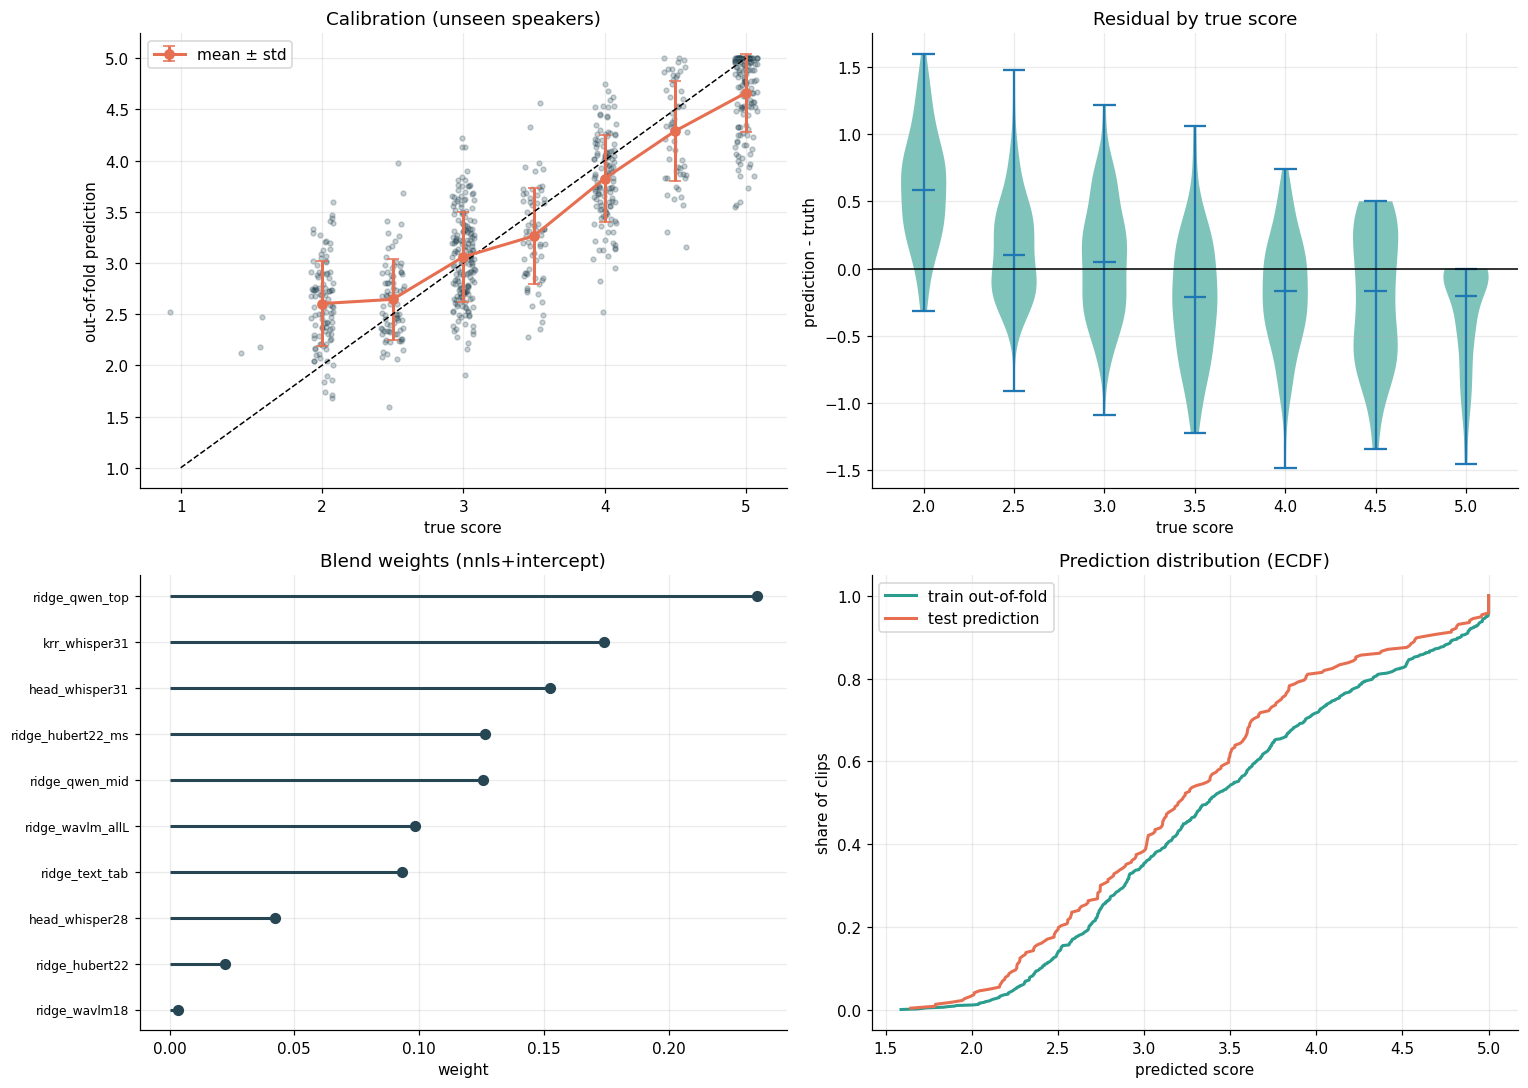

residual vs clip length r: -0.128 | residual vs word count r: -0.073
train OOF  mean/std: 3.473 0.857 | test pred mean/std: 3.299 0.838


In [11]:
# Cell 11 | diagnostic plots
require("blend_oof", "best_name", "blend_w", "final_test", "target_nz", "nz_pos", "clips", "PALETTE", "root_mse")

pred_oof = blend_oof[best_name]
resid = pred_oof - target_nz
levels = [s for s in sorted(set(target_nz)) if (target_nz == s).sum() >= 5]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. calibration: mean prediction per true score
mu = [pred_oof[target_nz == s].mean() for s in levels]
sd = [pred_oof[target_nz == s].std() for s in levels]
axes[0, 0].scatter(target_nz + np.random.uniform(-0.08, 0.08, len(target_nz)), pred_oof,
                   s=10, alpha=0.25, color=PALETTE["accent"])
axes[0, 0].errorbar(levels, mu, yerr=sd, fmt="o-", color=PALETTE["test"], capsize=4, lw=2, label="mean ± std")
axes[0, 0].plot([1, 5], [1, 5], "k--", lw=1)
axes[0, 0].set(title="Calibration (unseen speakers)", xlabel="true score", ylabel="out-of-fold prediction")
axes[0, 0].legend()

# 2. residual spread per level
parts = axes[0, 1].violinplot([resid[target_nz == s] for s in levels], showmedians=True)
for b in parts["bodies"]:
    b.set_facecolor(PALETTE["train"])
    b.set_alpha(0.6)
axes[0, 1].axhline(0, color="k", lw=1)
axes[0, 1].set_xticks(range(1, len(levels) + 1))
axes[0, 1].set_xticklabels([str(s) for s in levels])
axes[0, 1].set(title="Residual by true score", xlabel="true score", ylabel="prediction - truth")

# 3. blend weights
w = blend_w[blend_w > 1e-3].sort_values()
axes[1, 0].hlines(range(len(w)), 0, w.values, color=PALETTE["accent"], lw=2)
axes[1, 0].scatter(w.values, range(len(w)), color=PALETTE["accent"], s=40, zorder=3)
axes[1, 0].set_yticks(range(len(w)))
axes[1, 0].set_yticklabels(w.index, fontsize=8)
axes[1, 0].set(title=f"Blend weights ({best_name})", xlabel="weight")

# 4. do test predictions look like train out-of-fold predictions?
for vals, name, col in [(pred_oof, "train out-of-fold", PALETTE["train"]), (final_test, "test prediction", PALETTE["test"])]:
    xs = np.sort(vals)
    axes[1, 1].plot(xs, np.arange(1, len(xs) + 1) / len(xs), label=name, color=col, lw=2)
axes[1, 1].set(title="Prediction distribution (ECDF)", xlabel="predicted score", ylabel="share of clips")
axes[1, 1].legend()
plt.tight_layout()
plt.show()

print("residual vs clip length r:", round(float(np.corrcoef(resid, clips["seconds"].to_numpy()[nz_pos])[0, 1]), 3),
      "| residual vs word count r:", round(float(np.corrcoef(resid, clips["n_words"].to_numpy()[nz_pos])[0, 1]), 3))
print("train OOF  mean/std:", round(pred_oof.mean(), 3), round(pred_oof.std(), 3),
      "| test pred mean/std:", round(final_test.mean(), 3), round(final_test.std(), 3))

## 12. Submission file
Save `submission.csv` after checking that the rows, columns and score range are correct.

In [12]:
# Cell 12 | write submission.csv
require("clips", "test_df", "sample_df", "test_pos", "final_test", "OUT_DIR")

submission = pd.DataFrame({"filename": clips.loc[test_pos, "fname"].to_numpy(), "label": final_test})

assert list(submission["filename"]) == list(test_df["filename"]), "row order differs from test.csv"
assert list(submission.columns) == list(sample_df.columns), f"columns differ from sample_submission: {list(sample_df.columns)}"
assert submission["label"].notna().all() and submission["label"].between(0, 5).all()
assert submission["filename"].is_unique

submission.to_csv(f"{OUT_DIR}/submission.csv", index=False)
print("rows written:", len(submission), "| test.csv rows:", len(test_df), "| sample_submission rows:", len(sample_df))
print("file names shared with sample_submission:", len(set(submission["filename"]) & set(sample_df["filename"])))
print(submission["label"].describe().round(3))
submission.head()

rows written: 216 | test.csv rows: 216 | sample_submission rows: 204
file names shared with sample_submission: 25
count    216.000
mean       3.299
std        0.840
min        1.645
25%        2.656
50%        3.203
75%        3.798
max        5.000
Name: label, dtype: float64


,filename,label
0,audio_128.wav,3.009054
1,audio_156.wav,4.414154
2,audio_19.wav,4.567675
3,audio_108.wav,1.958686
4,audio_206.wav,2.013702


## 13. Results summary
Training RMSE, as the competition requires, on all 769 training clips and on the 732 non-zero clips. Out-of-fold is measured on speakers the models never saw and is the honest estimate for new data. Frame heads are left out of this table.

In [18]:
# Cell 13b | training RMSE on all 769 clips, including the 37 score-0 clips
require("clips", "train_pos", "target", "nz_mask", "nz_pos", "target_nz", "base_specs", "oof_store",
        "make_folds", "nnls_blender", "BLEND_SEEDS", "LOW", "HIGH", "root_mse")
from scipy.stats import pearsonr

# frame heads are left out: they only exist as out-of-fold predictions on non-zero clips
names_nh = [n for n in oof_store if n in base_specs]
S_nh = np.column_stack([oof_store[n] for n in names_nh])         # (732, k) out-of-fold predictions
blender = nnls_blender(S_nh, target_nz)

# base models refit on non-zero clips, then predict every training clip (score-0 clips were never seen)
P = []
for n in names_nh:
    maker, X = base_specs[n]
    X = np.asarray(X, dtype=np.float32)
    P.append(maker().fit(X[nz_pos], target_nz).predict(X[train_pos]))
pred_in = np.clip(blender["predict"](np.column_stack(P)), LOW, HIGH)    # (769,)

# out-of-fold version for the non-zero clips; score-0 clips are unseen by every model anyway
oof_nh = np.zeros(len(target_nz))
for seed in BLEND_SEEDS:
    for fit, val in make_folds(seed):
        p = nnls_blender(S_nh[fit], target_nz[fit])["predict"](S_nh[val])
        oof_nh[val] += np.clip(p, LOW, HIGH) / len(BLEND_SEEDS)
pred_oof = pred_in.copy()
pred_oof[nz_mask] = oof_nh

zero = ~nz_mask
rows = [
    ("all 769 clips, in-sample", root_mse(target, pred_in), pearsonr(target, pred_in)[0]),
    ("all 769 clips, out-of-fold", root_mse(target, pred_oof), pearsonr(target, pred_oof)[0]),
    ("732 non-zero clips, out-of-fold", root_mse(target_nz, oof_nh), pearsonr(target_nz, oof_nh)[0]),
]
print(pd.DataFrame(rows, columns=["measure", "RMSE", "Pearson"]).set_index("measure").round(4).to_string())
print(f"\nscore-0 clips: mean prediction {pred_in[zero].mean():.2f} (true 0.00), "
      f"RMSE on them {root_mse(target[zero], pred_in[zero]):.3f}")
print("note: frame heads are excluded here, so the 732-clip number differs slightly from the one printed in Cell 10")

                                   RMSE  Pearson
measure                                         
all 769 clips, in-sample         0.5971   0.8895
all 769 clips, out-of-fold       0.7219   0.8253
732 non-zero clips, out-of-fold  0.5244   0.8560

score-0 clips: mean prediction 2.29 (true 0.00), RMSE on them 2.322
note: frame heads are excluded here, so the 732-clip number differs slightly from the one printed in Cell 10


In [29]:
submission.to_csv("/kaggle/working/submission.csv", index=False)

import os
print("File exists:", os.path.exists("/kaggle/working/submission.csv"))
print("File size:", os.path.getsize("/kaggle/working/submission.csv"))

File exists: True
File size: 6762


# Report

## 1. Problem
Predict a 0-5 grammar score for 45-60 second spoken clips. Training data: 769 clips. Test data: 216 clips. Leaderboard metrics: RMSE and Pearson correlation.

## 2. Approach
Each clip is described in two ways: by the words and how they are spoken (from a transcript), and by the sound itself (from pretrained speech models). A simple model is trained on each description, and their predictions are blended into one score. All pretrained models are openly released; no external data and no paid APIs are used.

## 3. Preprocessing
- **Transcription.** Whisper large-v3 (faster-whisper), English, with word timestamps. Voice-activity filtering is off so pauses stay visible, and a short prompt with fillers stops Whisper from tidying up the speech.
- **Fluency features (21).** Speaking rate, pause counts and lengths, filler, repeat and restart rates, sentence length, vocabulary variety, word length and clause words, plus Whisper's own confidence.
- **Language-model features.** Qwen2.5-1.5B reads each transcript with fillers and cut-off words removed. I keep 7 surprisal statistics (mean, median, spread, high-surprise share and others) and the mean hidden state of two layers.
- **Audio embeddings.** WavLM-large, HuBERT-large and the Whisper-large-v3 encoder. Every layer is summarised by its mean and spread over time. For four layers the frame sequence is also kept for attention heads.
- **Score 0.** The 37 clips with score 0 form a single speaker group and look like "not a real answer" rather than the bottom of the scale. They are excluded from modelling.

## 4. Validation
The training set contains the same speakers many times, while the test speakers are new. A random split would reward voice recognition instead of grammar judgement. I link clips whose early-layer WavLM embeddings are very similar (cosine similarity above 0.95), which gives 413 speaker groups for 769 clips. All folds are 5-fold, stratified by score and grouped by speaker, and a check confirms that no speaker appears on both sides of any split. Every out-of-fold number below is measured on unseen speakers.

## 5. Pipeline
1. Whisper transcript -> fluency statistics and Qwen surprisal statistics -> ridge regression.
2. Qwen hidden states (two layers) -> ridge regression.
3. Speech-model embeddings (selected layers, mean/std) -> ridge or RBF kernel ridge.
4. Attention-pooling heads on the frame sequences of four layers.
5. A weighted blend of the out-of-fold predictions of all 14 models, with non-negative weights and an intercept, clipped to [1, 5]. A plain weighted average was tried as well and scored almost the same (0.5240 vs 0.5230); the first was used.

## 6. Results

| measure | clips | RMSE | Pearson |
|---|---|---|---|
| In-sample, final models (all features) | 732 non-zero | 0.3671 | 0.9329 |
| Out-of-fold, final models (all features) | 732 non-zero | 0.5230 | 0.8572 |
| Out-of-fold, without frame heads | 732 non-zero | 0.5244 | 0.8560 |
| In-sample, without frame heads | all 769 | 0.5971 | 0.8895 |
| Out-of-fold, without frame heads | all 769 | 0.7219 | 0.8253 |
| Score-0 clips alone, without frame heads | 37 | 2.322 | n/a |
| Public leaderboard | test | FILL IN | FILL IN |

The gap between in-sample (0.3671) and out-of-fold (0.5230) RMSE on the 732 clips shows how much the pipeline overfits; the out-of-fold number is the honest estimate for new speakers. The 37 score-0 clips were never seen by any model, so the all-clips RMSE is higher: the model predicts about 2.3 for them (true score 0).

Single models, out-of-fold RMSE: the best audio model is kernel ridge on Whisper layer 31 (0.5744). Qwen hidden states alone reach about 0.62, and fluency plus Qwen statistics reach 0.74.

## 7. What I learned
- Speech-model embeddings are the strongest signal. Mid-to-upper WavLM layers and the top Whisper encoder layers generalise best to new speakers.
- The language-model features add information the audio does not have: Qwen hidden states receive the largest blend weight (0.235 for the upper layer), followed by Whisper layer 31 (0.174).
- The attention heads add very little: removing them changes the out-of-fold RMSE by only 0.0014 (0.5230 to 0.5244).
- Predictions are pulled towards the middle of the scale, as the calibration plot shows.

## 8. Limitations
- Only 413 distinct training speakers; more speakers would help more than any model change.
- The 37 score-0 clips are excluded from modelling, so the model cannot recognise the "not a real answer" cluster and does badly on it (RMSE 2.32). No test clip has a voice similar to that group, but that shows the test speakers are different, not that the test set has no such answers.
- The attention heads use a fixed 30-epoch schedule, with no early stopping, and are weaker than the pooled-embedding models.
- The in-sample numbers for all 769 clips are not a measure of overfitting, because 37 of those clips were never seen by the models.